In [1]:
import pandas as pd
import numpy as np
import matplotlib as plt
import sklearn
import os

In [1]:
!gdown 1h86M8si2YT-aI4Zec1MeMP_mPYsLPy5F

The system cannot find the path specified.


In [2]:
import subprocess

subprocess.run(
    [r"C:\Program Files\7-Zip\7z.exe", "x", "./emg.rar", "-o./", "-y"],
    check=True
)

CompletedProcess(args=['C:\\Program Files\\7-Zip\\7z.exe', 'x', './emg.rar', '-o./', '-y'], returncode=0)

In [3]:
!tree "./EMG Physical Action Data Set/sub1"

Folder PATH listing for volume OS
Volume serial number is BEC2-5020
C:\USERS\SANGRAM PC\ONEDRIVE\DESKTOP\ALL DATA SCIENCE PART\DATA-SCIENCE-LEARNING\MACHINE_LEARNING\BOOSTING_AND_ENSEMBLE\EMG PHYSICAL ACTION DATA SET\SUB1
+---Aggressive
�   +---log
�   +---txt
+---Normal
    +---log
    +---txt


In [2]:
actions = {}

data_dirs = ["./EMG Physical Action Data Set/sub1/Aggressive/txt/",
             "./EMG Physical Action Data Set/sub1/Normal/txt/"]

ind = 0
data = pd.DataFrame()

for dirs in data_dirs :

  for files in os.listdir(dirs):

    with open(os.path.join(dirs, files), "r") as f:

      temp = pd.read_csv(f.name,
                        sep = "\t",
                        header = None, 
                        names = ["ch" + str(i) for i in range(1, 9)] # 8 input channels
                        )
      
      # chunking using Max of every 10 sequential values.
      temp_chunked = temp.groupby(np.arange(len(temp)) // 10).max().reset_index(drop=True)

      labels = [files[:-4] for i in range(len(temp_chunked))] # remove the last 4 characters=".txt" from the filename
      actions[files[:-4]] = ind

      temp_chunked["Action"] = labels

      data = pd.concat([data, temp_chunked])

      ind+=1

In [14]:
print(actions)

{'Elbowing': 0, 'Frontkicking': 1, 'Hamering': 2, 'Headering': 3, 'Kneeing': 4, 'Pulling': 5, 'Punching': 6, 'Pushing': 7, 'Sidekicking': 8, 'Slapping': 9, 'Bowing': 10, 'Clapping': 11, 'Handshaking': 12, 'Hugging': 13, 'Jumping': 14, 'Running': 15, 'Seating': 16, 'Standing': 17, 'Walking': 18, 'Waving': 19}


In [15]:
data.head(10)

,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8,Action
0,717,391,2615,-29,4000,205,1084,4000,Elbowing
1,1036,251,2989,162,4000,2971,3062,4000,Elbowing
2,3705,30,4000,549,4000,2940,-1767,-205,Elbowing
3,2679,347,1566,167,-4000,2758,-3965,785,Elbowing
4,1689,77,4000,-246,4000,2422,-1767,360,Elbowing
5,1365,55,4000,1024,4000,4000,4000,-37,Elbowing
6,2091,-213,4000,1684,4000,3807,4000,-2218,Elbowing
7,1311,605,4000,1106,3792,-3453,4000,-1662,Elbowing
8,1873,696,3658,2347,-4000,-2638,2244,-119,Elbowing
9,2211,811,4000,1045,4000,-1550,4000,56,Elbowing


In [16]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 19711 entries, 0 to 999
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ch1     19711 non-null  int64 
 1   ch2     19711 non-null  int64 
 2   ch3     19711 non-null  int64 
 3   ch4     19711 non-null  int64 
 4   ch5     19711 non-null  int64 
 5   ch6     19711 non-null  int64 
 6   ch7     19711 non-null  int64 
 7   ch8     19711 non-null  int64 
 8   Action  19711 non-null  object
dtypes: int64(8), object(1)
memory usage: 1.5+ MB


In [3]:
Y = data["Action"]
X = data.drop("Action", axis=1)

In [22]:
Y.unique()

array(['Elbowing', 'Frontkicking', 'Hamering', 'Headering', 'Kneeing',
       'Pulling', 'Punching', 'Pushing', 'Sidekicking', 'Slapping',
       'Bowing', 'Clapping', 'Handshaking', 'Hugging', 'Jumping',
       'Running', 'Seating', 'Standing', 'Walking', 'Waving'],
      dtype=object)

In [4]:
Y = Y.map(actions)
Y.head(10)

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: Action, dtype: int64

In [24]:
Y.value_counts()

Action
3     1000
2     1000
11    1000
4     1000
16    1000
18    1000
19    1000
14    1000
15     997
8      983
10     983
1      982
9      979
0      978
13     976
17     973
7      968
5      966
6      964
12     962
Name: count, dtype: int64

In [5]:
X = abs(X)

In [26]:
X.head(10)

,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8
0,717,391,2615,29,4000,205,1084,4000
1,1036,251,2989,162,4000,2971,3062,4000
2,3705,30,4000,549,4000,2940,1767,205
3,2679,347,1566,167,4000,2758,3965,785
4,1689,77,4000,246,4000,2422,1767,360
5,1365,55,4000,1024,4000,4000,4000,37
6,2091,213,4000,1684,4000,3807,4000,2218
7,1311,605,4000,1106,3792,3453,4000,1662
8,1873,696,3658,2347,4000,2638,2244,119
9,2211,811,4000,1045,4000,1550,4000,56


In [6]:
X = X.ewm(10).mean()

In [29]:
X.head(10)

,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8
0,717.000000,391.000000,2615.000000,29.000000,4000.000000,205.000000,1084.000000,4000.000000
1,884.095238,317.666667,2810.904762,98.666667,4000.000000,1653.857143,2120.095238,4000.000000
2,1915.302115,212.507553,3245.589124,263.290030,4000.000000,2124.018127,1991.018127,2612.703927
3,2134.324284,251.078862,2763.897005,235.674855,4000.000000,2305.838828,2557.139625,2088.533721
4,2027.528443,209.331985,3060.334147,238.150989,4000.000000,2333.696123,2367.651586,1674.003866
5,1889.236243,177.117655,3256.474342,402.184382,4000.000000,2681.510367,2708.378171,1332.305530
6,1926.912048,183.818047,3395.314578,641.540725,4000.000000,2891.675604,2949.565650,1497.693271
7,1821.958385,255.588990,3498.355182,720.686282,3964.556040,2987.327331,3128.563500,1525.691738
8,1830.015561,325.110086,3523.555921,977.408092,3970.151048,2932.184253,2988.930697,1303.638364
9,1886.382346,396.997673,3594.045993,987.408339,3974.567211,2727.689596,3138.518764,1119.049820


In [7]:
from sklearn.model_selection import train_test_split

X = np.array(X.values)
Y = np.array(Y.values)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, shuffle = True, random_state=3)

print(f"Sizes of the sets created are:\nTraining set: {X_train.shape[0]}\nTest set: {X_test.shape[0]}")

Sizes of the sets created are:
Training set: 15768
Test set: 3943


In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

tree_clf = DecisionTreeClassifier(random_state=7, max_depth = 7, )
cv_acc_results = cross_validate(tree_clf, X_train, Y_train, cv = 5, scoring = 'accuracy', return_train_score = True)

print(f"K-Fold Accuracy Mean: Train: {cv_acc_results['train_score'].mean().round(3)*100} Validation: {cv_acc_results['test_score'].mean().round(3)*100}")

K-Fold Accuracy Mean: Train: 68.7 Validation: 67.9


In [33]:
from sklearn.tree import DecisionTreeClassifier as dtc
from sklearn import tree
from sklearn.model_selection import GridSearchCV

params = {
    "max_depth": [3, 5, 7],
    "max_leaf_nodes": [15, 20, 25],
}
model1 = dtc()
clf = GridSearchCV(model1, params, cv=5, scoring='accuracy', return_train_score=True)
clf.fit(X_train, Y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 5, ...], 'max_leaf_nodes': [15, 20, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscore

In [35]:
res = clf.cv_results_

for i in range(len(res['params'])):
    print(f"Parameters: {res['params'][i]} Mean_score: {res['mean_test_score'][i].round(3)*100} rank: {res['rank_test_score'][i]}")

Parameters: {'max_depth': 3, 'max_leaf_nodes': 15} Mean_score: 32.5 rank: 7
Parameters: {'max_depth': 3, 'max_leaf_nodes': 20} Mean_score: 32.5 rank: 7
Parameters: {'max_depth': 3, 'max_leaf_nodes': 25} Mean_score: 32.5 rank: 7
Parameters: {'max_depth': 5, 'max_leaf_nodes': 15} Mean_score: 50.6 rank: 6
Parameters: {'max_depth': 5, 'max_leaf_nodes': 20} Mean_score: 50.7 rank: 5
Parameters: {'max_depth': 5, 'max_leaf_nodes': 25} Mean_score: 50.7 rank: 4
Parameters: {'max_depth': 7, 'max_leaf_nodes': 15} Mean_score: 64.1 rank: 3
Parameters: {'max_depth': 7, 'max_leaf_nodes': 20} Mean_score: 66.9 rank: 2
Parameters: {'max_depth': 7, 'max_leaf_nodes': 25} Mean_score: 67.60000000000001 rank: 1


In [37]:
import datetime as dt
from sklearn.ensemble import AdaBoostClassifier

model2 = AdaBoostClassifier(dtc(max_depth = 5))

params = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.1, 0.2, 0.3]
}

clf = GridSearchCV(model2, params, cv=5, scoring='accuracy', return_train_score=True)
clf.fit(X_train, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",AdaBoostClass...(max_depth=5))
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.1, 0.2, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this 

In [38]:
res = clf.cv_results_

for i in range(len(res['params'])):
    print(f"Parameters: {res['params'][i]} Mean_score: {res['mean_test_score'][i].round(3)*100} rank: {res['rank_test_score'][i]}")

Parameters: {'learning_rate': 0.1, 'n_estimators': 50} Mean_score: 87.5 rank: 9
Parameters: {'learning_rate': 0.1, 'n_estimators': 100} Mean_score: 89.2 rank: 7
Parameters: {'learning_rate': 0.1, 'n_estimators': 150} Mean_score: 90.5 rank: 4
Parameters: {'learning_rate': 0.2, 'n_estimators': 50} Mean_score: 88.9 rank: 8
Parameters: {'learning_rate': 0.2, 'n_estimators': 100} Mean_score: 90.4 rank: 5
Parameters: {'learning_rate': 0.2, 'n_estimators': 150} Mean_score: 90.9 rank: 3
Parameters: {'learning_rate': 0.3, 'n_estimators': 50} Mean_score: 89.5 rank: 6
Parameters: {'learning_rate': 0.3, 'n_estimators': 100} Mean_score: 91.0 rank: 2
Parameters: {'learning_rate': 0.3, 'n_estimators': 150} Mean_score: 91.4 rank: 1


In [8]:
x = np.arange(0, 50)
x = pd.DataFrame({'x':x})

In [9]:
y1 = np.random.uniform(10, 15, 10)
y2 = np.random.uniform(20, 25, 10)
y3 = np.random.uniform(0, 5, 10)
y4 = np.random.uniform(30, 32, 10)
y5 = np.random.uniform(12, 17, 10)

y = np.concatenate([y1, y2, y3, y4, y5])
y = y[:, None]

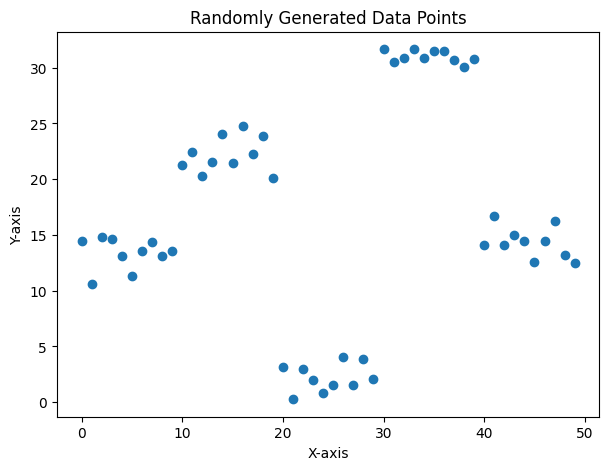

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 5))
plt.plot(x, y, 'o')
plt.title("Randomly Generated Data Points")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.show()

In [19]:
from IPython.display import display
from fastai.imports import *
from sklearn import metrics
import datetime as dt

In [20]:
from sklearn.ensemble import GradientBoostingClassifier as GBC

start = dt.datetime.now()
model3 = GBC(n_estimators=150, learning_rate=0.2, max_depth=4, random_state=0, verbose=1).fit(X_train, Y_train)
end = dt.datetime.now()
print(f"Time taken for training: {end - start}\nTraning accuracy: {model3.score(X_train, Y_train)} test accuracy: {model3.score(X_test, Y_test)}")

      Iter       Train Loss   Remaining Time 
         1           1.0069            1.97m
         2           0.7759            1.99m
         3           0.6285            1.96m
         4           0.5240            1.96m
         5           0.4464            1.91m
         6           0.3842            1.88m
         7           0.3387            1.85m
         8           0.3021            1.86m
         9           0.2739            1.84m
        10           0.2491            1.82m
        20           0.1334            1.70m
        30           0.0887            1.57m
        40           0.0638            1.43m
        50           0.0481            1.29m
        60           0.0369            1.15m
        70           0.0292            1.02m
        80           0.0234           53.64s
        90           0.0189           45.68s
       100           0.0152           37.85s
Time taken for training: 0:01:50.195531
Traning accuracy: 1.0 test accuracy: 0.9601826020796348


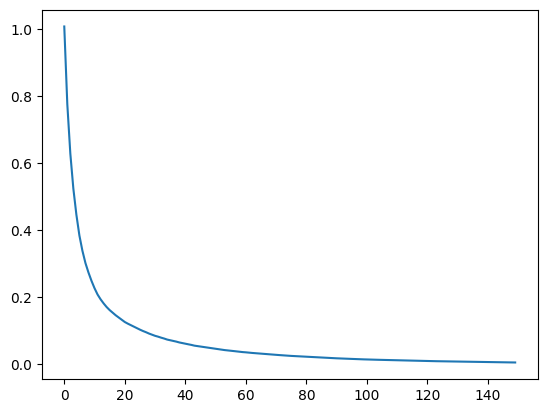

In [21]:
plt.plot(model3.train_score_, label='Training Score')